# dicompare tutorial: checking a multisite protocol in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/astewartau/dicompare/blob/main/examples/dicompare_tutorial.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/astewartau/dicompare/main?labpath=examples%2Fdicompare_tutorial.ipynb)

[dicompare](https://github.com/astewartau/dicompare) checks that MRI acquisitions match a protocol, using only
the DICOM headers. It runs offline: nothing is uploaded anywhere.

This notebook walks through a multisite check from start to finish:

1. Write two small synthetic sessions: a reference site and a second site that has drifted from the protocol.
2. Load a session into a pandas DataFrame.
3. Build a protocol schema from the reference site.
4. Map the second site's acquisitions to the schema.
5. Check the second site with `check_session()`.
6. Look at the results as a table and charts.
7. Allow for differences you accept between sites.
8. Check against a published guideline from dicompare's schema library.
9. Save a report, and run the same check from the command line.

All the data is made up: a numerical phantom with a few slices per volume.

The next cell installs dicompare (and `matplotlib` and `jinja2`, for the charts and the coloured table) if they
are missing, for example on Colab.

In [1]:
import importlib.util

packages = {"dicompare": "git+https://github.com/astewartau/dicompare", "matplotlib": "matplotlib", "jinja2": "jinja2"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    %pip install -q {" ".join(missing)}

In [2]:
import pandas as pd

from dicompare import (build_schema, check_session, load_bundled_schema, load_dicom_session, map_session,
                       save_report, save_schema)
from dicompare.examples import write_multisite_example

## 1. Example data

You would normally point dicompare at your own DICOM folders. Here `write_multisite_example()` writes two small
synthetic sessions of the same protocol: a T1-weighted MPRAGE, a five-echo GRE for QSM (magnitude and phase),
and a T2-weighted FLAIR. The **reference site** (`site_A`) runs the protocol as intended. The **second site**
(`site_B`) has drifted in ways that are common in practice:

| Acquisition | Reference site | Second site |
|---|---|---|
| T1w MPRAGE | TR 2400 ms, TE 2.14 ms, 0.8 mm voxels | TR 2300 ms, TE 2.98 ms, 1 mm voxels |
| QSM multi-echo GRE | 1 mm slices | 2 mm slices |
| T2w FLAIR | present | **missing** |

The second site also names its protocols differently, so dicompare has to work out which scan is which.

In [3]:
sites = write_multisite_example("dicompare_tutorial_data")
sites

{'site_A': PosixPath('dicompare_tutorial_data/site_A'),
 'site_B': PosixPath('dicompare_tutorial_data/site_B')}

## 2. Load a session

`load_dicom_session()` reads the DICOM headers under a folder into a DataFrame, with one row per file and one
column per DICOM field. You don't need to do this before checking, but it shows what dicompare sees.

In [4]:
site_a = load_dicom_session(sites["site_A"])
columns = ["ProtocolName", "ImageType", "EchoTime", "RepetitionTime", "FlipAngle", "SliceThickness"]
site_a[columns].drop_duplicates().sort_values(["ProtocolName", "EchoTime"])

,ProtocolName,ImageType,EchoTime,RepetitionTime,FlipAngle,SliceThickness
7,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",4.00,30.0,12.0,1.0
11,QSM_ME_GRE,"(ORIGINAL, PRIMARY, P)",4.00,30.0,12.0,1.0
18,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",10.00,30.0,12.0,1.0
22,QSM_ME_GRE,"(ORIGINAL, PRIMARY, P)",10.00,30.0,12.0,1.0
21,QSM_ME_GRE,"(ORIGINAL, PRIMARY, P)",16.00,30.0,12.0,1.0
16,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",16.00,30.0,12.0,1.0
20,QSM_ME_GRE,"(ORIGINAL, PRIMARY, P)",22.00,30.0,12.0,1.0
14,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",22.00,30.0,12.0,1.0
8,QSM_ME_GRE,"(ORIGINAL, PRIMARY, P)",28.00,30.0,12.0,1.0
9,QSM_ME_GRE,"(ORIGINAL, PRIMARY, M)",28.00,30.0,12.0,1.0


## 3. Build a schema from the reference site

A **schema** describes the protocol: for each acquisition, the value each field must have. `build_schema()`
makes one from a session, using the fields that define how a scan is acquired (TR, TE, flip angle, slice
thickness, ...). dicompare names each acquisition after its protocol, for example `acq-t1wmpr`.

In a real study you would build the schema once from a pilot scan at the lead site, review it (the
[dicompare web app](https://dicompare.neurodesk.org/) has an editor), and share the JSON file with every site.

In [5]:
schema = build_schema(site_a)
save_schema(schema, "protocol.json")
list(schema["acquisitions"])

['acq-qsmmegre', 'acq-t1wmpr', 'acq-t2wflair']

In [6]:
# The fields required for the T1 scan
pd.DataFrame(schema["acquisitions"]["acq-t1wmpr"]["fields"])[["field", "value"]]

,field,value
0,MRAcquisitionType,3D
1,SliceThickness,0.8
2,RepetitionTime,2400.0
3,EchoTime,2.14
4,InversionTime,1000.0
5,FlipAngle,8.0
6,NumberOfAverages,1.0
7,MagneticFieldStrength,3.0
8,PixelBandwidth,200.0
9,ReceiveCoilName,HeadNeck_64


## 4. Map the second site's acquisitions to the schema

The second site called its scans `t1_mprage_sag` and `gre_qsm_5echo`, so dicompare can't match them by name.
Instead it scores every pairing of a schema acquisition with a site acquisition by how far their fields differ,
and picks the pairing with the lowest total. The score is the **cost**: 0 means every field matches.

The cost is summarised as a **confidence**: `exact` (cost 0), `high` (below 5), `medium` (below 20) or `low`.
A low-confidence match is worth checking by eye. Schema acquisitions with nothing left to match are
**unmapped**.

`check_session()` maps automatically, but `map_session()` shows the mapping on its own:

In [7]:
map_session(sites["site_B"], schema)

,reference_acquisition,input_acquisition,mapping_cost,mapping_confidence
0,acq-qsmmegre,acq-greqsm5echo,1.0,high
1,acq-t1wmpr,acq-t1mpragesag,11.04,medium
2,acq-t2wflair,None,None,None


The QSM scan matches with high confidence (only its slice thickness differs) and the T1 with medium
confidence (TR, TE and slice thickness differ). The FLAIR is unmapped. If a mapping is ever wrong, give your own:
`check_session(..., mapping={"acq-t1wmpr": "acq-t1mpragesag", ...})`.

## 5. Check the second site

`check_session()` takes a session (a folder or a DataFrame) and a schema (a JSON file or a dict), maps the
acquisitions and checks every field. It returns a DataFrame with **one row per check**: the mapping, the
`field` checked, the `expected` value and the `value` found, a `message`, and a `status` of `ok`, `error`,
`warning`, `na` (field not found) or `unmapped`.

In [8]:
results = check_session(sites["site_B"], "protocol.json")
results.head()

,reference_acquisition,input_acquisition,mapping_cost,mapping_confidence,field,series,rule_name,value,expected,message,passed,status
0,acq-qsmmegre,acq-greqsm5echo,1.0,high,MRAcquisitionType,None,None,[3D],3D,Passed.,True,ok
1,acq-qsmmegre,acq-greqsm5echo,1.0,high,SliceThickness,None,None,[2.0],1.0,Expected 1.0 but got 2.0,False,error
2,acq-qsmmegre,acq-greqsm5echo,1.0,high,RepetitionTime,None,None,[30.0],30.0,Passed.,True,ok
3,acq-qsmmegre,acq-greqsm5echo,1.0,high,FlipAngle,None,None,[12.0],12.0,Passed.,True,ok
4,acq-qsmmegre,acq-greqsm5echo,1.0,high,NumberOfAverages,None,None,[1.0],1.0,Passed.,True,ok


In [9]:
pd.crosstab(results["reference_acquisition"], results["status"])

status,error,ok,unmapped
reference_acquisition,,,
acq-qsmmegre,1,17,0
acq-t1wmpr,3,8,0
acq-t2wflair,0,0,1


## 6. Look at the results

Everything that did not pass, coloured by status:

In [10]:
colours = {"error": "#f8d7da", "warning": "#fff3cd", "na": "#e2e3e5", "unmapped": "#e8dff5"}
problems = results[results["status"] != "ok"]
problems[["reference_acquisition", "field", "expected", "value", "status", "message"]].style.map(
    lambda status: f"background-color: {colours.get(status, '')}", subset=["status"])

,reference_acquisition,field,expected,value,status,message
1,acq-qsmmegre,SliceThickness,1.000000,[2.0],error,Expected 1.0 but got 2.0
19,acq-t1wmpr,SliceThickness,0.800000,[1.0],error,Expected 0.8 but got 1.0
20,acq-t1wmpr,RepetitionTime,2400.000000,[2300.0],error,Expected 2400.0 but got 2300.0
21,acq-t1wmpr,EchoTime,2.140000,[2.98],error,Expected 2.14 but got 2.98
29,acq-t2wflair,None,None,None,unmapped,No input acquisition mapped to reference acquisition 'acq-t2wflair'


A summary per acquisition:

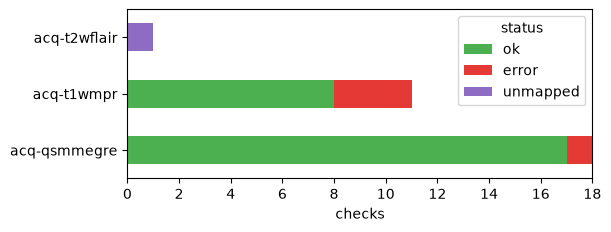

In [11]:
counts = pd.crosstab(results["reference_acquisition"], results["status"])[["ok", "error", "unmapped"]]
ax = counts.plot.barh(stacked=True, figsize=(6, 2.2), color={"ok": "#4caf50", "error": "#e53935", "unmapped": "#8e6cc4"})
ax.set(xlabel="checks", ylabel="");

And how far off each failed value is. Values come back as a list of the distinct values found (one here), so
`.str[0]` takes the value out of the list:

In [12]:
failed = results[results["status"] == "error"].copy()
failed.index = failed["reference_acquisition"] + " " + failed["field"]
failed["actual"] = failed["value"].str[0]
failed["difference (%)"] = 100 * (failed["actual"] / failed["expected"] - 1)
failed[["expected", "actual", "difference (%)"]].astype(float).round(2)

,expected,actual,difference (%)
acq-qsmmegre SliceThickness,1.00,2.00,100.00
acq-t1wmpr SliceThickness,0.80,1.00,25.00
acq-t1wmpr RepetitionTime,2400.00,2300.00,-4.17
acq-t1wmpr EchoTime,2.14,2.98,39.25


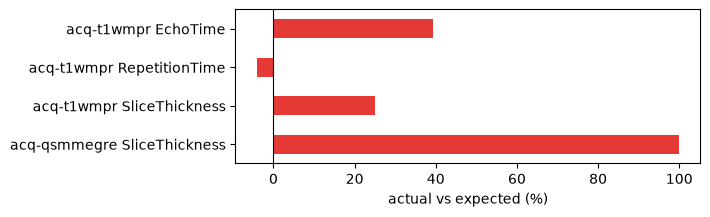

In [13]:
ax = failed["difference (%)"].astype(float).plot.barh(figsize=(6, 2), color="#e53935")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="actual vs expected (%)");

## 7. Allow for differences you accept

Not every difference matters. If your study accepts a TR within ±150 ms, add a `tolerance` to that field in the
schema. (Other constraints work the same way: `min`/`max` for a range, `contains` for text.)

In [14]:
for field in schema["acquisitions"]["acq-t1wmpr"]["fields"]:
    if field["field"] == "RepetitionTime":
        field["tolerance"] = 150

relaxed = check_session(sites["site_B"], schema)
relaxed[relaxed["status"] == "error"][["reference_acquisition", "field", "expected", "value"]]

,reference_acquisition,field,expected,value
1,acq-qsmmegre,SliceThickness,1.0,[2.0]
19,acq-t1wmpr,SliceThickness,0.8,[1.0]
21,acq-t1wmpr,EchoTime,2.14,[2.98]


The TR failure is gone; the other three remain.

## 8. Check against a published guideline

dicompare ships schemas for published protocols and guidelines (see `dicompare.list_bundled_schemas()`). These
often contain **rules**: small Python checks that encode the guideline's reasoning, such as "the voxels are
isotropic". The QSM consensus guideline has a single acquisition, so we tell `check_session()` which scan to
check against it:

In [15]:
_, qsm_guideline, _ = load_bundled_schema("QSM_Consensus_Guidelines_v1.0.json")
guideline = check_session(sites["site_B"], qsm_guideline,
                          mapping={"Quantitative Susceptibility Mapping (QSM)": "acq-greqsm5echo"})
guideline[["rule_name", "status", "message"]]

,rule_name,status,message
0,None,ok,Passed.
1,Isotropic Voxels,error,Voxels not isotropic (tolerance 0.1 mm). Pixel...
2,Voxel Size Limit,error,Voxel size should be <= 1 mm³. Got 2.00 mm³.
3,Multi-echo Validation,ok,OK
4,Uniform Echo Spacing,ok,OK
5,Short First Echo,ok,OK
6,TE Close to T2*,ok,OK
7,Valid Magnitude/Phase Pairs,ok,OK
8,Matching Magnitude/Phase Slices,ok,OK
9,Readout Bandwidth,ok,OK


The second site's 2 mm slices break two of the guideline's rules: its voxels are no longer isotropic, and their
volume is above the recommended limit.

## 9. Save a report, and use the command line

`save_report()` writes the results as JSON, in the same format as the `dicompare check` command:

In [16]:
save_report(results, "site_B_report.json")

In a pipeline you may not want Python at all. `dicompare check` does the same as `check_session()` and **exits
with status 1** if any check fails or an acquisition is unmapped (0 otherwise), so a script can stop or flag a
session. `--auto-yes` accepts the automatic mapping instead of asking:

In [17]:
!dicompare check dicompare_tutorial_data/site_B protocol.json site_B_report.json --auto-yes; echo "exit status: $?"


Acquisition Mapping:
--------------------------------------------------------------------------------
  Reference                           Input                       Cost  Confidence
--------------------------------------------------------------------------------
  acq-qsmmegre                        acq-greqsm5echo              1.0  high
  acq-t1wmpr                          acq-t1mpragesag             11.0  medium
  acq-t2wflair                        (unmapped)                    --  --
--------------------------------------------------------------------------------



=== acq-qsmmegre  ->  acq-greqsm5echo ===
  17 passed, 1 failed (18 total)

  [FAIL] SliceThickness
         expected: 1.0
         got:      [2.0]
         Expected 1.0 but got 2.0

=== acq-t1wmpr  ->  acq-t1mpragesag ===
  8 passed, 3 failed (11 total)

  [FAIL] SliceThickness
         expected: 0.8
         got:      [1.0]
         Expected 0.8 but got 1.0
  [FAIL] RepetitionTime
         expected: 2400.0
         got:      [2300.0]
         Expected 2400.0 but got 2300.0
  [FAIL] EchoTime
         expected: 2.14
         got:      [2.98]
         Expected 2.14 but got 2.98

  [WARN] Acquisition unmapped: 'acq-t2wflair'

Use --verbose to see all 29 results including passes.
Compliance report saved to site_B_report.json


exit status: 1


Checking many sessions is then a shell loop:

```bash
for session in sessions/*/; do
    dicompare check "$session" protocol.json "reports/$(basename "$session").json" --auto-yes \
        || echo "$session: not compliant"
done
```

## Next steps

- Check your own data: `check_session("/path/to/session", "protocol.json")`.
- Edit schemas, add rules and browse the schema library in the
  [dicompare web app](https://dicompare.neurodesk.org/), which runs the same package in your browser.
- See the [README](https://github.com/astewartau/dicompare#python-api) for the rest of the Python API.

This notebook wrote `dicompare_tutorial_data/`, `protocol.json` and `site_B_report.json`; delete them when you're
done.